In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.datasets import make_blobs

In [2]:
X, y = make_blobs(
    n_samples=300,
    centers=4,
    cluster_std=1.5,
    random_state=42
)

df = pd.DataFrame(
    X,
    columns=['Annual Income', 'Spending Score']
)

print(df.head())

print("\nDataset Shape:")
print(df.shape)

   Annual Income  Spending Score
0      -9.527369        6.048756
1     -10.128948        6.746690
2      -1.275380        7.183021
3      -7.206149       -5.231944
4     -11.895515        5.811393

Dataset Shape:
(300, 2)


In [3]:
print("Dataset Information:")
print(df.info())

print("\nStatistical Description:")
print(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Annual Income   300 non-null    float64
 1   Spending Score  300 non-null    float64
dtypes: float64(2)
memory usage: 4.8 KB
None

Statistical Description:
       Annual Income  Spending Score
count     300.000000      300.000000
mean       -3.407346        2.839134
std         5.408295        6.293198
min       -12.545795       -9.938958
25%        -7.972913       -1.651604
50%        -4.629173        4.717279
75%        -0.025263        8.133557
max         8.111867       12.709149

Missing Values:
Annual Income     0
Spending Score    0
dtype: int64


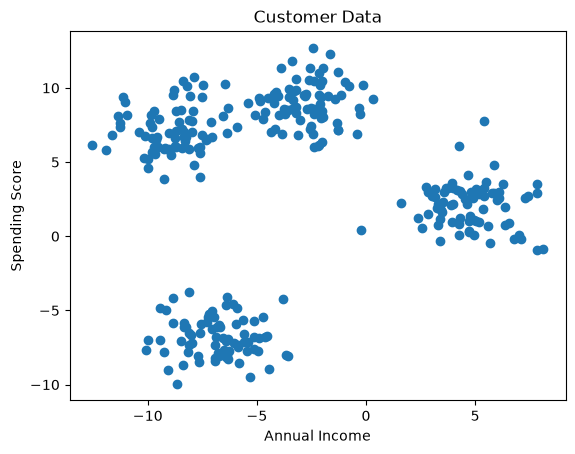

In [4]:
plt.scatter(
    df['Annual Income'],
    df['Spending Score']
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")

plt.title("Customer Data")

plt.show()

In [6]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(df)

print("Scaled Data:")
print(X_scaled[:5])

Scaled Data:
[[-1.13349006  0.51086669]
 [-1.2449085   0.62195479]
 [ 0.39486157  0.6914044 ]
 [-0.70357666 -1.28465123]
 [-1.5720945   0.47308629]]


In [7]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans.fit(X_scaled)

kmeans_labels = kmeans.labels_

print("K-Means Cluster Labels:")
print(kmeans_labels)

K-Means Cluster Labels:
[3 3 0 1 3 1 2 1 0 2 0 2 0 0 3 0 3 2 0 0 2 0 1 3 0 3 3 1 1 2 0 2 3 2 3 0 3
 1 3 1 2 0 3 1 0 0 3 2 3 2 1 3 1 0 1 2 3 2 2 0 3 2 2 0 1 1 1 1 1 0 1 1 3 2
 0 3 1 1 0 1 0 0 3 0 1 3 3 2 2 2 3 0 3 0 0 3 1 0 3 3 2 2 2 0 0 0 0 0 1 3 2
 0 0 0 0 2 3 1 3 1 1 1 0 3 1 3 3 0 3 1 2 0 0 0 0 2 2 3 0 1 0 2 1 0 2 2 2 2
 1 0 0 3 2 1 0 2 1 3 3 2 3 3 1 3 2 3 1 0 0 0 0 0 1 2 2 1 1 2 2 1 3 0 3 2 2
 3 1 0 2 2 1 1 1 3 2 1 1 2 2 3 0 0 1 2 0 1 1 3 1 0 0 1 1 2 3 1 3 3 0 3 3 1
 3 1 2 2 3 3 2 2 2 3 0 1 2 1 3 2 3 3 3 1 1 2 3 1 1 1 3 1 3 1 3 2 1 3 2 0 3
 0 2 0 3 0 1 2 1 2 2 0 0 1 2 2 3 3 1 0 0 2 2 2 2 1 3 2 1 2 2 1 0 1 2 0 3 0
 2 0 3 3]


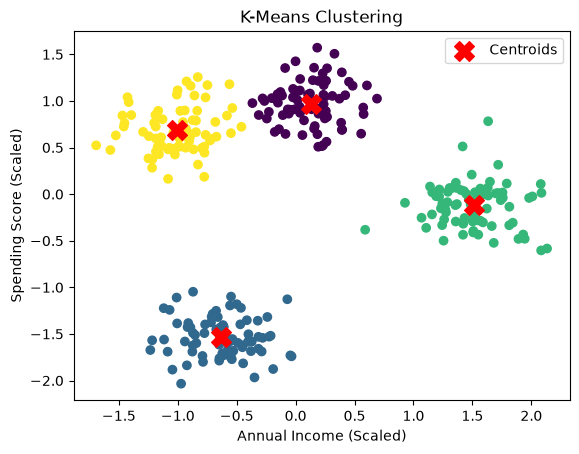

In [8]:
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    cmap='viridis'
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    color='red',
    marker='X',
    s=200,
    label='Centroids'
)

plt.title("K-Means Clustering")
plt.xlabel("Annual Income (Scaled)")
plt.ylabel("Spending Score (Scaled)")

plt.legend()
plt.show()

In [9]:
dbscan = DBSCAN(
    eps=0.3,
    min_samples=5
)

dbscan.fit(X_scaled)

dbscan_labels = dbscan.labels_

print("DBSCAN Cluster Labels:")
print(dbscan_labels)

DBSCAN Cluster Labels:
[ 0  0  0  1  0  1  2  1  0  2  0  2  0  0  0  0  0  2  0  0  2  0  1  0
  0  0  0  1  1  2  0  2  0  2  0  0  0  1  0  1  2  0  0  1  0  0  0  2
  0  2  1  0  1  0  1 -1  0  2  2  0  0  2  2  0  1  1  1  1  1  0  1  1
  0  2  0  0  1  1  0  1  0  0  0  0  1  0  0  2  2  2  0  0  0  0  0  0
  1  0  0  0  2  2  2  0  0  0  0  0  1  0  2  0  0  0  0  2  0  1  0  1
  1  1  0  0  1  0  0  0  0  1  2  0  0  0  0  2  2  0  0  1  0  2  1  0
  2  2  2  2  1  0  0  0  2  1  0  2  1  0  0  2  0  0  1  0  2  0  1  0
  0  0  0  0  1  2  2  1  1 -1  2  1  0  0  0  2  2  0  1  0 -1  2  1  1
  1  0  2  1  1  2  2  0  0  0  1  2  0  1  1  0  1  0  0  1  1  2  0  1
  0  0  0  0  0  1  0  1  2  2  0  0  2  2  2  0  0  1  2  1  0  2  0  0
  0  1  1  2  0  1  1  1  0  1  0  1  0  2  1  0  2  0  0  0  2  0  0  0
  1  2  1  2  2  0  0  1  2  2  0  0  1  0  0  2  2  2  2  1  0  2  1  2
  2  1  0  1  2  0  0  0  2  0  0  0]


In [10]:
n_clusters = len(set(dbscan_labels)) - (
    1 if -1 in dbscan_labels else 0
)

n_noise = list(dbscan_labels).count(-1)

print("Number of Clusters:", n_clusters)

print("Number of Noise Points:", n_noise)

Number of Clusters: 3
Number of Noise Points: 3


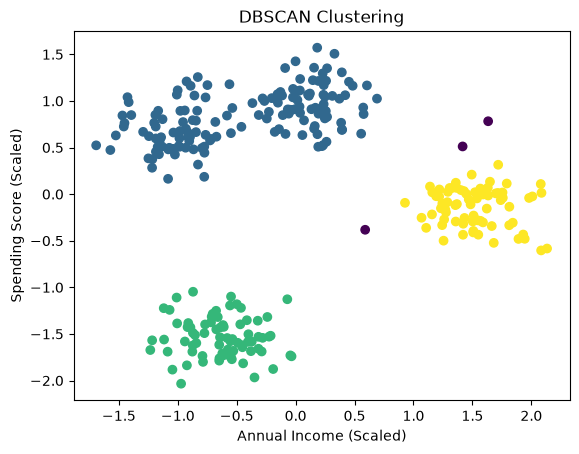

In [11]:
plt.scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=dbscan_labels,
    cmap='viridis'
)

plt.title("DBSCAN Clustering")
plt.xlabel("Annual Income (Scaled)")
plt.ylabel("Spending Score (Scaled)")

plt.show()

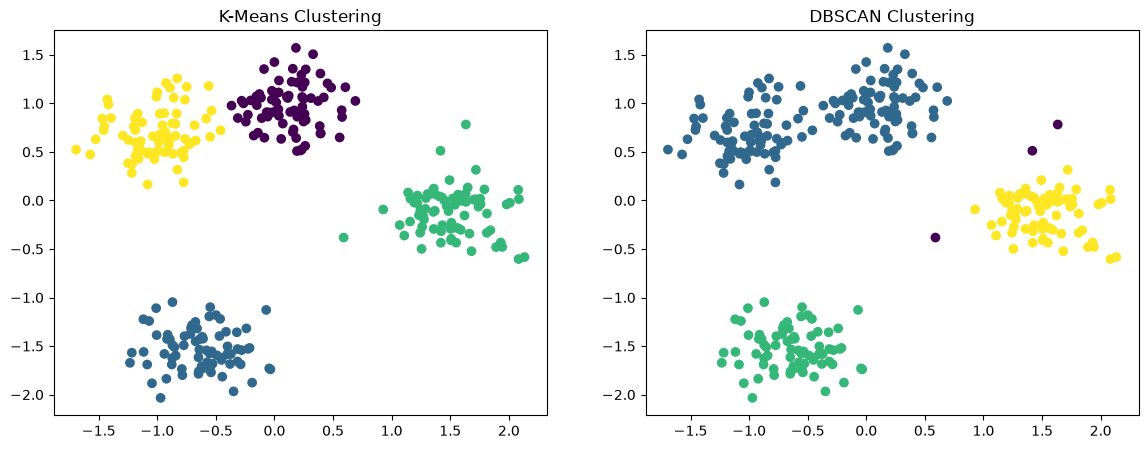

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    cmap='viridis'
)

axes[0].set_title("K-Means Clustering")

axes[1].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=dbscan_labels,
    cmap='viridis'
)

axes[1].set_title("DBSCAN Clustering")

plt.show()

In [13]:
print("K-Means Results:")
print("Number of Clusters:", len(set(kmeans_labels)))
print("Inertia:", kmeans.inertia_)

print("\nDBSCAN Results:")
print("Number of Clusters:", n_clusters)
print("Number of Noise Points:", n_noise)

K-Means Results:
Number of Clusters: 4
Inertia: 37.219665959542525

DBSCAN Results:
Number of Clusters: 3
Number of Noise Points: 3
